Dabbord, creer un nouveau venv, qui utilise le python du venv de l'app (je sais, pas propre, mais ça marche de façon fiable)

In [1]:
%pip install kaggle
%pip install --no-build-isolation -r requirements-stylegan.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached click-8.1.7-py3-none-any.whl (97 kB)
  Using cached requests-2.32.3-py3-none-any.whl (64 kB)
  Using cached tqdm-4.66.5-py3-none-any.whl (78 kB)
  Using cached ninja-1.11.1.4-py3-none-win_amd64.whl (296 kB)
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.70.1
    Uninstalling tqdm-4.70.1:
      Successfully uninstalled tqdm-4.70.1
  Attempting uninstall: requests
    Found existing installation: requests 2.34.2
    Uninstalling requests-2.34.2:
      Successfully uninstalled requests-2.34.2
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Attention ! pour charger le module, faut avoir [WIN USER PATH]/.kaggle/kaggle.json, téléchargable en créant une legacy api key.
Ensuite, créer une vrai api key (la recommended en suivant les instruction dans les params de son compte kaggle (le machin juste au dessus))
Et magie ! notre code à ce qu'il lui faut pour se connecter en votre nom, et pas le notre !

In [1]:
import os
from pathlib import Path
# 1. Définir les identifiants via access_token dans .kaggle
os.environ['KAGGLE_CONFIG_DIR'] = str(Path.home() / ".kaggle")

# 2. Importer l'API et s'authentifier
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

# 3. Préparer le dossier
dataset_dir = Path("raw_dataset")
dataset_dir.mkdir(exist_ok=True)

print("Connexion réussie ! Téléchargement et extraction de CelebA-HQ (environ 3 Go)...")
print("Veuillez patienter, cela peut prendre plusieurs minutes sans afficher de barre de progression.")

# 4. Télécharger et décompresser via le code Python directement
api.dataset_download_files('lamsimon/celebahq', path=str(dataset_dir), unzip=True)

print("Téléchargement et extraction terminés avec succès !")

Connexion réussie ! Téléchargement et extraction de CelebA-HQ (environ 3 Go)...
Veuillez patienter, cela peut prendre plusieurs minutes sans afficher de barre de progression.
Dataset URL: https://www.kaggle.com/datasets/lamsimon/celebahq


KeyboardInterrupt: 

In [6]:
# Vérifier combien d'images ont été téléchargées
# CelebA-HQ contient généralement les images dans un sous-dossier (ex: celeba_hq_256 ou data)
import os
from pathlib import Path
dataset_dir = Path("raw_dataset")
image_files = list(dataset_dir.rglob("*.jpg")) + list(dataset_dir.rglob("*.png"))

print(f"Nombre d'images trouvées : {len(image_files)}")
if len(image_files) > 0:
    print(f"Exemple de chemin : {image_files[0]}")

Nombre d'images trouvées : 30000
Exemple de chemin : raw_dataset\celeba_hq\train\female\000004.jpg


## Préparer les exemples de remplacement SimSwap 512

Une cellule par traitement, depuis le dossier de l'application. Après un redémarrage
du noyau, exécuter **PARAMÈTRES ET OUTILS**, puis directement l'étape souhaitée.
Chaque étape recharge ses index sur disque et charge ses modèles seulement si nécessaire.
Les cellules de chargement des modèles sont facultatives (préchauffage).

Les résultats existants sont réutilisés ; les progrès sont enregistrés après chaque
élément dans des journaux JSONL. Une interruption reprend au premier résultat manquant
ou incomplet. Les nouveaux NPY sont publiés par renommage atomique après écriture complète.
La reprise de Y contrôle l'en-tête, la forme, le type et la taille des fichiers, sans
relire leur contenu en entier. Elle ne constitue pas un contrôle d'intégrité bit à bit.
Les anciens crops, embeddings et Y sont repris sans conversion de format.
Les checkpoints doivent déjà être installés dans son gestionnaire de modèles.

- `X0` : crop de l'image à éditer, aligné par le backend de l'application.
- `X1` : crop d'un donneur fictif généré par StyleGAN2-ADA, aligné de la même façon.
- `E1` : identité du donneur calculée avec **l'ArcFace historique de SimSwap**.
- `Y` : sortie brute du générateur SimSwap 512 pour `(X0, E1)`.

Le contrat du générateur est RGB float32 `[B, 3, 512, 512]` en `[0, 1]`,
avec une identité `[B, 512]` normalisée L2. Les crops PNG restent sans perte ;
`Y` est enregistré en NPY float32 CHW pour conserver exactement la sortie du maître.
Aucun masque, BiSeNet ou blending ne fait partie de ces cibles : la recomposition
reste une étape du backend après le générateur, lors de l'utilisation dans l'application.

Les valeurs ci-dessous sont ajustables pour le jeu expérimental. Quelques donneurs ne
suffisent pas à démontrer la généralisation à des identités inconnues.
Deux cibles par image représentent environ 6 Mo par image source, hors crops.

In [7]:
# --- 1. PARAMÈTRES ET OUTILS ---
import gc
import hashlib
import json
import logging
import os
from types import SimpleNamespace
import random
from pathlib import Path

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from src.utils.config import Settings
from src.utils.image_utils import EXTENSIONS, load_image, save_image
from src.utils.model_manager import ModelManager, sha256
from src.backends.insightface_backend import InsightFaceBackend
from src.backends.stylegan_backend import StyleGANBackend
from src.backends.simswap_backend import SimSwapBackend

logging.getLogger().setLevel(logging.ERROR)
settings = Settings(device="cuda" if torch.cuda.is_available() else "cpu",
                    crop_size=512, segmentation=False)
input_dir = Path("raw_dataset")
output_dir = Path("processed_dataset_512/distillation")
num_identities = 20
first_seed = 1000
truncation = 0.7
max_images = None  # None pour utiliser tout le dataset
donors_per_image = 2
validation_fraction = 0.2
split_seed = 42

if not 2 <= donors_per_image <= num_identities or not 0 < validation_fraction < 1:
    raise ValueError("Vérifier le nombre de donneurs et la fraction de validation")
for folder in ("synthetic_originals", "X0", "X1", "E1", "Y"):
    (output_dir / folder).mkdir(parents=True, exist_ok=True)

def write_json(path, data):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
    temporary.replace(path)

# Empêcher la réutilisation silencieuse de cibles produites avec d'autres modèles.
manager = ModelManager(settings)
model_hashes = {key: sha256(manager.require(key))
                for key in ("stylegan", "simswap512", "arcface", "detector", "recognizer")}
configuration = dict(version=1, crop_size=512, alignment="ffhq", color="RGB",
                     image_range=[0, 1], identity="SimSwap ArcFace L2, ImageNet puis nearest 112",
                     Y_format="float32 CHW NPY, sortie brute sans masque",
                     model_hashes=model_hashes, num_identities=num_identities,
                     first_seed=first_seed, truncation=truncation,
                     preprocessing_hashes={name: sha256(settings.root / name) for name in (
                         "src/backends/simswap_backend.py", "src/backends/insightface_backend.py",
                         "src/backends/stylegan_backend.py", "src/utils/image_utils.py")})
config_path = output_dir / "configuration.json"
if config_path.exists() and json.loads(config_path.read_text(encoding="utf-8")) != configuration:
    raise ValueError("Configuration différente : choisir un autre output_dir pour ce dataset")
write_json(config_path, configuration)
print(f"SimSwap 512 sur {settings.device} ; dataset : {output_dir}")

# --- REPRISE DEPUIS LES FICHIERS, SANS RELANCER LES ÉTAPES PRÉCÉDENTES ---
def read_json(name, default=None):
    path = output_dir / name
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    if default is not None:
        return default
    raise FileNotFoundError(f"{name} absent : exécuter l'étape qui le produit")

def read_progress(name):
    path = output_dir / name
    if not path.exists():
        return []
    records = []
    # Seule une dernière ligne interrompue peut être réparée ; une erreur au milieu est signalée.
    with path.open("r+b") as stream:
        while True:
            offset = stream.tell()
            line = stream.readline()
            if not line:
                break
            try:
                record = json.loads(line)
            except (ValueError, UnicodeDecodeError):
                if stream.read(1):
                    raise ValueError(f"Journal corrompu avant sa dernière ligne : {name}")
                stream.truncate(offset)
                break
            records.append(record)
            if not line.endswith(b"\n"):
                stream.seek(0, 2)
                stream.write(b"\n")
                break
    return records

def append_progress(name, record):
    with (output_dir / name).open("a", encoding="utf-8") as stream:
        stream.write(json.dumps(record, ensure_ascii=False) + "\n")
        stream.flush()
        os.fsync(stream.fileno())

def indexed_records(name, key):
    rows = read_json(name + ".json", []) + read_progress(name + ".progress.jsonl")
    return {row[key]: row for row in rows}

def valid_png(path):
    try:
        with Image.open(path) as image:
            if image.size != (512, 512) or image.mode != "RGB":
                return False
        with path.open("rb") as stream:
            stream.seek(-12, 2)
            return stream.read() == b"\x00\x00\x00\x00IEND\xaeB`\x82"
    except (OSError, ValueError):
        return False

def valid_array(path, shape):
    try:
        array = np.load(path, mmap_mode="r", allow_pickle=False)
        valid = (array.shape == shape and array.dtype == np.float32
                 and path.stat().st_size == array.offset + array.nbytes)
        array._mmap.close()
        return valid
    except (OSError, ValueError, EOFError):
        return False

def save_array(path, array):
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("wb") as stream:
        np.save(stream, array, allow_pickle=False)
        stream.flush()
        os.fsync(stream.fileno())
    temporary.replace(path)

def get_recognizer():
    global recognizer, recognizer_settings
    if globals().get("recognizer_settings") != settings:
        recognizer = InsightFaceBackend(settings)
        recognizer_settings = settings
    return recognizer

def get_teacher():
    global teacher, teacher_settings
    if globals().get("teacher_settings") != settings:
        teacher = SimSwapBackend(settings)
        teacher_settings = settings
    return teacher

def current_sources():
    return read_json("sources.json")

def pair_plan():
    sources = current_sources()
    donors = read_json("donors.json")
    if len(sources) < 2 or len(donors) < donors_per_image:
        raise ValueError("Préparer les index X0 et X1/E1 avant les insertions")
    rng = random.Random(split_seed)
    plan = []
    for source in sources:
        # Conserver l'ordre et le tirage de la version initiale pour reprendre ses Y.
        for donor in rng.sample(donors, donors_per_image):
            key = f"{source['key']}_{donor['key']}"
            inputs = dict(X0=source["X0_sha256"], E1=donor["E1_sha256"],
                          configuration=configuration)
            fingerprint = hashlib.sha256(json.dumps(inputs, sort_keys=True).encode()).hexdigest()
            plan.append(dict(key=key, source_id=source["key"], donor_id=donor["key"],
                             X0=source["X0"], X1=donor["X1"], E1=donor["E1"],
                             Y=f"Y/{key}.npy", fingerprint=fingerprint))
    return sources, plan

print("Reprise prête : lancer directement l'étape souhaitée après cette cellule.")

SimSwap 512 sur cpu ; dataset : processed_dataset_512\distillation
Reprise prête : lancer directement l'étape souhaitée après cette cellule.


In [ ]:
# --- 2. CHARGEMENT FACULTATIF DU DÉTECTEUR DE L'APPLICATION ---
# Les autres étapes le chargent automatiquement si leur cache ne suffit pas.
recognizer = get_recognizer()
print("Détecteur prêt !")

In [ ]:
# --- 3. GÉNÉRATION DES IDENTITÉS FICTIVES PAR STYLEGAN ---
cached = indexed_records("synthetic_faces", "seed")
synthetic_faces = []
stylegan = None
try:
    for seed in range(first_seed, first_seed + num_identities * 10):
        path = output_dir / "synthetic_originals" / f"seed_{seed}.png"
        if not path.exists():
            if stylegan is None:
                stylegan = StyleGANBackend(settings)
            save_image(path, stylegan.generate(seed, truncation=truncation))
        digest = sha256(path)
        item = cached.get(seed)
        if item is None or item["original_sha256"] != digest:
            faces = get_recognizer().detect(load_image(path))
            item = dict(seed=seed, path=path.relative_to(output_dir).as_posix(),
                        original_sha256=digest, face_count=len(faces))
            if len(faces) == 1:
                item["landmarks"] = faces[0].landmarks.tolist()
            append_progress("synthetic_faces.progress.jsonl", item)
        if item["face_count"] != 1:
            continue
        synthetic_faces.append(item)
        print(f"Identité fictive {len(synthetic_faces)}/{num_identities} : seed {seed}")
        if len(synthetic_faces) == num_identities:
            break
finally:
    del stylegan
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
if len(synthetic_faces) != num_identities:
    raise RuntimeError("Pas assez de portraits synthétiques à un seul visage")
write_json(output_dir / "synthetic_faces.json", synthetic_faces)
print("Portraits et landmarks enregistrés pour les étapes suivantes.")

In [ ]:
# --- 4. CHARGEMENT FACULTATIF DU MAÎTRE SIMSWAP 512 SANS BISENET ---
teacher = get_teacher()
assert teacher.size == 512 and teacher.parser is None
print("Maître prêt ! Les étapes suivantes peuvent aussi le charger automatiquement.")

In [ ]:
# --- 5. ALIGNEMENT DES DONNEURS X1 ET CALCUL DE LEUR IDENTITÉ E1 ---
cached = indexed_records("donors", "key")
synthetic_faces = read_json("synthetic_faces.json", [])
# Compatibilité avec les donneurs déjà préparés avant l'ajout de la reprise.
if not synthetic_faces and len(cached) == num_identities:
    synthetic_faces = [dict(seed=row["seed"]) for row in cached.values()]
if not synthetic_faces:
    raise FileNotFoundError("Préparer les portraits StyleGAN avant les donneurs")
donors, reused = [], 0
for item in synthetic_faces:
    key = f"seed_{item['seed']}"
    x1_path = output_dir / "X1" / f"{key}.png"
    e1_path = output_dir / "E1" / f"{key}.npy"
    old = cached.get(key)
    original_hash = item.get("original_sha256")
    if old and old.get("original_sha256") and original_hash and old["original_sha256"] != original_hash:
        raise ValueError(f"Le donneur {key} a changé : conserver les Y dans leur dataset d'origine")
    if old and valid_png(x1_path) and valid_array(e1_path, (512,)):
        if sha256(x1_path) != old["X1_sha256"] or sha256(e1_path) != old["E1_sha256"]:
            raise ValueError(f"X1 ou E1 modifié pour {key} : ne pas réutiliser ses anciens Y")
        donors.append(old)
        reused += 1
        continue
    if "landmarks" not in item:
        raise FileNotFoundError(f"Landmarks de {key} absents : relancer seulement la cellule StyleGAN")
    model = get_teacher()
    face = SimpleNamespace(landmarks=np.asarray(item["landmarks"], dtype=np.float32))
    crop, matrix = model._align(load_image(output_dir / item["path"]), face)
    with torch.inference_mode():
        source = model._tensor(crop)
        arc_input = F.interpolate((source - model.mean) / model.std, (112, 112), mode="nearest")
        identity = F.normalize(model.arcface(arc_input), p=2, dim=1)
    if identity.shape != (1, 512) or not torch.isfinite(identity).all():
        raise ValueError(f"Embedding SimSwap invalide pour {key}")
    save_image(x1_path, crop)
    save_array(e1_path, identity[0].cpu().numpy())
    row = dict(key=key, seed=item["seed"], X1=x1_path.relative_to(output_dir).as_posix(),
               E1=e1_path.relative_to(output_dir).as_posix(), original_sha256=original_hash,
               X1_sha256=sha256(x1_path), E1_sha256=sha256(e1_path), matrix=matrix.tolist())
    append_progress("donors.progress.jsonl", row)
    donors.append(row)
write_json(output_dir / "donors.json", donors)
print(f"{len(donors)} donneurs prêts, dont {reused} réutilisés sans inférence.")

In [ ]:
# --- 6. PRÉTRAITEMENT DU DATASET POUR OBTENIR X0 ---
image_files = sorted(path for path in input_dir.rglob("*")
                     if path.is_file() and path.suffix.lower() in EXTENSIONS)
if max_images is not None:
    image_files = image_files[:max_images]
cached = indexed_records("sources", "original")
sources, reused = [], 0
for index, img_path in enumerate(image_files):
    relative = img_path.relative_to(input_dir).as_posix()
    stat = img_path.stat()
    old = cached.get(relative)
    # Avec les anciens index, calculer le hash une seule fois pour ajouter les stats.
    unchanged = old and old.get("original_size") == stat.st_size and old.get("original_mtime_ns") == stat.st_mtime_ns
    source_hash = old["original_sha256"] if unchanged else sha256(img_path)
    if old and old["original_sha256"] == source_hash:
        if old.get("status") == "no_face" or valid_png(output_dir / old["X0"]):
            if not unchanged:
                old = dict(old, original_size=stat.st_size, original_mtime_ns=stat.st_mtime_ns)
                append_progress("sources.progress.jsonl", old)
            if old.get("status") != "no_face":
                sources.append(old)
            reused += 1
            continue
    image = load_image(img_path)
    faces = get_recognizer().detect(image)
    row = dict(original=relative, original_sha256=source_hash,
               original_size=stat.st_size, original_mtime_ns=stat.st_mtime_ns)
    if not faces:
        append_progress("sources.progress.jsonl", dict(row, status="no_face"))
        continue
    main_face = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))
    crop, matrix = get_teacher()._align(image, main_face)
    key = hashlib.sha256((relative + source_hash).encode("utf-8")).hexdigest()[:20]
    x0_path = output_dir / "X0" / f"{key}.png"
    save_image(x0_path, crop)
    row.update(key=key, status="ok", X0=x0_path.relative_to(output_dir).as_posix(),
               X0_sha256=sha256(x0_path), matrix=matrix.tolist())
    append_progress("sources.progress.jsonl", row)
    sources.append(row)
    if (index + 1) % 50 == 0:
        print(f"{index + 1}/{len(image_files)} images examinées")
if len(sources) < 2:
    raise ValueError("Il faut au moins deux images X0 pour séparer entraînement et validation")
write_json(output_dir / "sources.json", sources)
print(f"{len(sources)} crops X0 prêts ; {reused} entrées reprises sans détection ni alignement.")

In [8]:
# --- 7. INSERTIONS SIMSWAP : PRODUCTION DES TRIPLETS (X0, X1, Y) ---
# Recharger les index, même après redémarrage du noyau. Aucun prétraitement antérieur à relancer.
sources, plan = pair_plan()
completed = indexed_records("pairs", "key")
pairs, reused, generated_count = [], 0, 0
current_x0, x0 = None, None
for index, pair in enumerate(plan):
    y_path = output_dir / pair["Y"]
    old = completed.get(pair["key"])
    if old and old.get("fingerprint", pair["fingerprint"]) != pair["fingerprint"]:
        raise ValueError(f"Les entrées de {pair['key']} ont changé : conserver ses anciens Y")
    if valid_array(y_path, (3, 512, 512)):
        # Migration des anciens Y et récupération d'un résultat publié avant une interruption.
        if old != pair:
            append_progress("pairs.progress.jsonl", pair)
        reused += 1
    else:
        model = get_teacher()  # Aucun chargement du maître si tous les Y existent déjà.
        if current_x0 != pair["X0"]:
            x0 = model._tensor(load_image(output_dir / pair["X0"]))
            current_x0 = pair["X0"]
        identity = torch.from_numpy(np.load(output_dir / pair["E1"], allow_pickle=False)).unsqueeze(0)
        with torch.inference_mode():
            generated = model.generator(x0, identity.to(model.device))
        if generated.shape != x0.shape or not torch.isfinite(generated).all():
            raise ValueError(f"Sortie SimSwap invalide : {pair['key']}")
        if generated.min() < 0 or generated.max() > 1:
            raise ValueError(f"Sortie hors du domaine [0, 1] : {pair['key']}")
        save_array(y_path, generated[0].cpu().numpy())
        append_progress("pairs.progress.jsonl", pair)
        generated_count += 1
    pairs.append(pair)
    if (index + 1) % 100 == 0:
        print(f"{index + 1}/{len(plan)} Y : {reused} repris, {generated_count} générés")
write_json(output_dir / "pairs.json", pairs)
print(f"{len(pairs)} triplets prêts : {reused} Y repris, {generated_count} générés sans BiSeNet.")

100/59990 Y : 0 repris, 100 générés
200/59990 Y : 0 repris, 200 générés
300/59990 Y : 0 repris, 300 générés
400/59990 Y : 0 repris, 400 générés
500/59990 Y : 0 repris, 500 générés
600/59990 Y : 0 repris, 600 générés
700/59990 Y : 0 repris, 700 générés
800/59990 Y : 0 repris, 800 générés
900/59990 Y : 0 repris, 900 générés
1000/59990 Y : 0 repris, 1000 générés
1100/59990 Y : 0 repris, 1100 générés
1200/59990 Y : 0 repris, 1200 générés
1300/59990 Y : 0 repris, 1300 générés
1400/59990 Y : 0 repris, 1400 générés
1500/59990 Y : 0 repris, 1500 générés
1600/59990 Y : 0 repris, 1600 générés
1700/59990 Y : 0 repris, 1700 générés
1800/59990 Y : 0 repris, 1800 générés
1900/59990 Y : 0 repris, 1900 générés
2000/59990 Y : 0 repris, 2000 générés
2100/59990 Y : 0 repris, 2100 générés
2200/59990 Y : 0 repris, 2200 générés
2300/59990 Y : 0 repris, 2300 générés
2400/59990 Y : 0 repris, 2400 générés
2500/59990 Y : 0 repris, 2500 générés
2600/59990 Y : 0 repris, 2600 générés
2700/59990 Y : 0 repris, 2700 

In [9]:
# --- 8. SÉPARATION ENTRAÎNEMENT / VALIDATION ET MANIFESTE ---
# Lire les petits index seulement : pas de chargement de modèles ou des pixels de Y.
sources, plan = pair_plan()
completed = indexed_records("pairs", "key")
pairs = []
for pair in plan:
    old = completed.get(pair["key"])
    if old is None or old.get("fingerprint", pair["fingerprint"]) != pair["fingerprint"]:
        raise ValueError("Génération Y incomplète : relancer uniquement la cellule INSERTIONS SIMSWAP")
    pairs.append(pair)
source_ids = [source["key"] for source in sources]
random.Random(split_seed).shuffle(source_ids)
val_count = max(1, min(len(source_ids) - 1, round(len(source_ids) * validation_fraction)))
val_ids = set(source_ids[:val_count])
records = [dict(pair, split="validation" if pair["source_id"] in val_ids else "train")
           for pair in pairs]
manifest = dict(configuration=read_json("configuration.json"), split_seed=split_seed,
                validation_fraction=validation_fraction, records=records)
write_json(output_dir / "manifest.json", manifest)
print(f"Train : {sum(row['split'] == 'train' for row in records)} triplets")
print(f"Validation : {sum(row['split'] == 'validation' for row in records)} triplets")
print("Validation sur des X0 distincts ; les donneurs sont partagés entre les splits.")

Train : 47992 triplets
Validation : 11998 triplets
Validation sur des X0 distincts ; les donneurs sont partagés entre les splits.


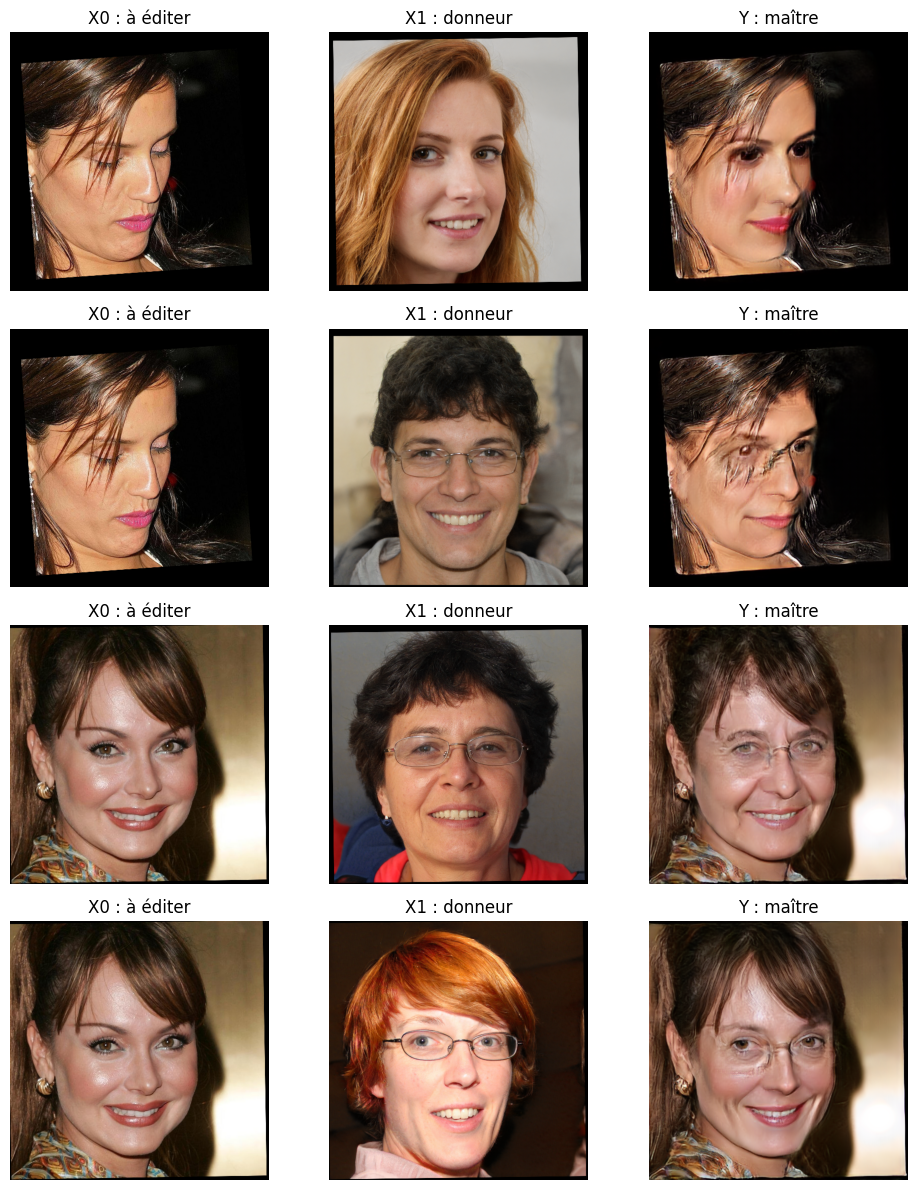

In [10]:
# --- 9. VÉRIFICATION VISUELLE DES TRIPLETS ---
records = read_json("manifest.json")["records"]
preview = records[:min(4, len(records))]
fig, axes = plt.subplots(len(preview), 3, figsize=(10, 3 * len(preview)), squeeze=False)
for row, record in enumerate(preview):
    images = [load_image(output_dir / record["X0"])[..., ::-1],
              load_image(output_dir / record["X1"])[..., ::-1],
              np.load(output_dir / record["Y"], allow_pickle=False).transpose(1, 2, 0)]
    for col, (title, image) in enumerate(zip(("X0 : à éditer", "X1 : donneur", "Y : maître"), images)):
        axes[row, col].imshow(image)
        axes[row, col].set_title(title)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()